In [1]:
import pandas as pd

# 1. Chargement du fichier CSV
file_path = '/content/openfoodfacts_cleaned.csv'
df = pd.read_csv(file_path)

# Affichage des premières lignes
print("--- Aperçu des 5 premières lignes ---")
display(df.head())


FileNotFoundError: [Errno 2] No such file or directory: '/content/openfoodfacts_cleaned.csv'

In [ ]:
# 2. Informations générales (Dimensions et valeurs manquantes)
print(f"Nombre de lignes : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}\n")

print("--- Nombre de lignes vides (valeurs manquantes) par colonne ---")
display(df.isna().sum().to_frame(name='Valeurs Manquantes'))


In [ ]:
# 3. Filtrage pour l'arrivage / vente en France uniquement
df_france = df[df['countries_en'] == 'France']
print(f"Filtrage effectué sur la colonne 'countries_en' pour la valeur 'France'")

print(f"Nombre de lignes après filtrage : {df_france.shape[0]}")

Filtrage effectué sur la colonne 'countries_en' pour la valeur 'France'
Nombre de lignes après filtrage : 642578


In [ ]:
import numpy as np
import pandas as pd

# ==========================================
# 1. ANALYSE DU NUTRI-SCORE (VALEURS DE -15 À +40)
# ==========================================

nutri_col = 'nutrition-score-fr_100g'

# Nous filtrons uniquement les lignes qui ont un Nutri-Score renseigné (non nul)
nutri_filtered = df_france[df_france[nutri_col].notna()].copy()

# Pour chaque valeur unique de score (de -15 à 40), on compte le nombre de produits (lignes)
score_counts = nutri_filtered[nutri_col].value_counts().sort_index()

# Nous calculons ensuite la proportion que représente chaque score sur le total (multiplié par 100 pour le %)
score_pcts = (nutri_filtered[nutri_col].value_counts(normalize=True) * 100).sort_index()

# Création d'un tableau synthétique pour afficher les effectifs et les pourcentages par valeur de score
df_detailed_scores = pd.DataFrame({
    'Nombre de lignes': score_counts,
    'Pourcentage (%)': score_pcts.round(2)
})

print("--- Répartition détaillée du score nutritionnel (-15 à +40) ---")
display(df_detailed_scores)

# ==========================================
# 2. REGROUPEMENT DU NUTRI-SCORE EN 5 CATÉGORIES (A, B, C, D, E)
# ==========================================

# Définition de la fonction de classification selon les tranches demandées
def attribuer_categorie(score):
    if -15 <= score <= -1:
        return 'A'
    elif 0 <= score <= 2:
        return 'B'
    elif 3 <= score <= 10:
        return 'C'
    elif 11 <= score <= 18:
        return 'D'
    elif 19 <= score <= 40:
        return 'E'
    return np.nan

# Application de la fonction pour créer une nouvelle colonne contenant la catégorie A, B, C, D ou E
nutri_filtered['nutriscore_categorie'] = nutri_filtered[nutri_col].apply(attribuer_categorie)

# Comptage des effectifs et des pourcentages pour chaque catégorie créée
cat_counts = nutri_filtered['nutriscore_categorie'].value_counts().sort_index()
cat_pcts = (nutri_filtered['nutriscore_categorie'].value_counts(normalize=True) * 100).sort_index()

# Assemblage des résultats dans un tableau récapitulatif pour le Nutri-Score
df_nutri_categories = pd.DataFrame({
    'Nombre de lignes': cat_counts,
    'Pourcentage (%)': cat_pcts.round(2)
})

print("\n--- Tableau récapitulatif par catégorie Nutri-Score (A à E) ---")
display(df_nutri_categories)

# ==========================================
# 3. ANALYSE DE L'ECO-SCORE (COLONNE 'ecoscore_grade')
# ==========================================

eco_col = 'ecoscore_grade'

# Nous filtrons uniquement les lignes qui ont un Eco-Score renseigné (non nul)
eco_filtered = df_france[df_france[eco_col].notna()].copy()

# Harmonisation en majuscules par sécurité pour éviter les doublons dus à la casse (ex: 'a' vs 'A')
eco_filtered[eco_col] = eco_filtered[eco_col].astype(str).str.upper()

# Comptage des effectifs et des pourcentages par lettre de l'Eco-Score
eco_counts = eco_filtered[eco_col].value_counts().sort_index()
eco_pcts = (eco_filtered[eco_col].value_counts(normalize=True) * 100).sort_index()

# Assemblage des résultats dans un tableau récapitulatif pour l'Eco-Score
df_eco_categories = pd.DataFrame({
    'Nombre de lignes': eco_counts,
    'Pourcentage (%)': eco_pcts.round(2)
})

print("\n--- Tableau récapitulatif par catégorie Écoscore (A à E) ---")
display(df_eco_categories)

--- Répartition détaillée du score nutritionnel (-15 à +40) ---


,Nombre de lignes,Pourcentage (%)
nutrition-score-fr_100g,,
-15.0,2,0.00
-14.0,19,0.01
-13.0,54,0.02
-12.0,216,0.07
-11.0,380,0.12
-10.0,372,0.11
-9.0,492,0.15
-8.0,727,0.22
-7.0,1062,0.33



--- Tableau récapitulatif par catégorie Nutri-Score (A à E) ---


,Nombre de lignes,Pourcentage (%)
nutriscore_categorie,,
A,47140,14.52
B,44316,13.65
C,71545,22.04
D,105990,32.65
E,55633,17.14



--- Tableau récapitulatif par catégorie Écoscore (A à E) ---


,Nombre de lignes,Pourcentage (%)
ecoscore_grade,,
A,14033,2.18
B,79168,12.32
C,58503,9.10
D,52437,8.16
E,42448,6.61
NOT-APPLICABLE,3768,0.59
UNKNOWN,392221,61.04


In [ ]:
# On définit notre sous-ensemble d'étude : uniquement la France et avec un Nutri-Score renseigné
df_france_nutri_valide = df_france[df_france['nutrition-score-fr_100g'].notna()]

print("--- Nombre de valeurs manquantes (NaN) par colonne pour le jeu de données France avec Nutri-Score renseigné ---")
print(f"Taille du sous-ensemble : {df_france_nutri_valide.shape[0]} lignes\n")

# Calcul du nombre de NaN
nan_counts_sub = df_france_nutri_valide.isna().sum().to_frame(name='Nombre de NaN')

# Calcul du pourcentage par rapport à ce sous-ensemble
nan_counts_sub['Pourcentage (%)'] = ((df_france_nutri_valide.isna().sum() / len(df_france_nutri_valide)) * 100).round(2)

display(nan_counts_sub)

--- Nombre de valeurs manquantes (NaN) par colonne pour le jeu de données France avec Nutri-Score renseigné ---
Taille du sous-ensemble : 324624 lignes



,Nombre de NaN,Pourcentage (%)
Unnamed: 0,0,0.00
product_name,0,0.00
generic_name,272989,84.09
quantity,153809,47.38
brands,83011,25.57
categories_en,0,0.00
origins_en,287750,88.64
countries_en,0,0.00
traces_en,268849,82.82
additives_n,158903,48.95


In [ ]:
# Liste des colonnes à supprimer demandées par l'utilisateur
columns_to_drop = [
    'vitamin-a_100g', 'vitamin-c_100g', 'potassium_100g', 'calcium_100g',
    'iron_100g', 'cholesterol_100g', 'trans-fat_100g', 'polyunsaturated-fat_100g',
    'monounsaturated-fat_100g', 'generic_name', 'quantity', 'origins_en', 'traces_en',
    'additives_en','ecoscore_score'
]

# Suppression des colonnes présentes dans notre sous-ensemble d'étude
# (Nous utilisons errors='ignore' par sécurité au cas où l'une des colonnes n'existait pas)
df_france_final = df_france_nutri_valide.drop(columns=columns_to_drop, errors='ignore')

# Affichage des dimensions du nouveau dataset
print("--- Dimensions du nouveau jeu de données final ---")
print(f"Nombre de lignes : {df_france_final.shape[0]}")
print(f"Nombre de colonnes restantes : {df_france_final.shape[1]}\n")

# Calcul et affichage du nombre et pourcentage de NaN pour les colonnes restantes
nan_counts_final = df_france_final.isna().sum().to_frame(name='Nombre de NaN')
nan_counts_final['Pourcentage (%)'] = ((df_france_final.isna().sum() / len(df_france_final)) * 100).round(2)

print("--- Valeurs manquantes (NaN) par colonne restante ---")
display(nan_counts_final)

--- Dimensions du nouveau jeu de données final ---
Nombre de lignes : 324624
Nombre de colonnes restantes : 21

--- Valeurs manquantes (NaN) par colonne restante ---


,Nombre de NaN,Pourcentage (%)
Unnamed: 0,0,0.00
product_name,0,0.00
brands,83011,25.57
categories_en,0,0.00
countries_en,0,0.00
additives_n,158903,48.95
nutriscore_score,0,0.00
food_groups_en,30744,9.47
ecoscore_grade,0,0.00
main_category_en,0,0.00


In [ ]:
# =====================================================================
# ÉQUILIBRAGE DU JEU DE DONNÉES EN PRIVILÉGIANT LES LIGNES SANS NAN
# =====================================================================

# 1. Calcul du nombre de NaN pour chaque ligne (axe 1)
df_france_final = df_france_final.copy()
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

# Recréation de la colonne de catégorie Nutri-Score sur ce dataset final
# (au cas où elle n'avait pas été conservée lors du drop)
df_france_final['nutriscore_categorie'] = df_france_final['nutrition-score-fr_100g'].apply(attribuer_categorie)

# 2. Détermination de la taille cible pour l'équilibrage
# On regarde la taille actuelle de chaque catégorie
counts_by_cat = df_france_final['nutriscore_categorie'].value_counts()
print("Nombre de lignes initiales par catégorie :")
print(counts_by_cat)

# La taille cible sera dictée par la plus petite catégorie pour garantir une proportion équivalente (1:1:1:1:1).
min_cat_size = counts_by_cat.min()

# Ajustement de la taille cible selon les limites demandées (entre 10 000 et 300 000 lignes par classe)
target_size = max(10000, min(300000, min_cat_size))
print(f"\nTaille cible choisie par catégorie : {target_size} lignes (Total pour le dataset : {target_size * 5} lignes)\n")

# 3. Échantillonnage stratifié en éliminant en priorité les lignes avec le plus de NaN
balanced_chunks = []

for cat in ['A', 'B', 'C', 'D', 'E']:
    # Isolation de la catégorie courante
    df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]

    # Tri des lignes : celles ayant le moins de NaN en premier
    df_cat_sorted = df_cat.sort_values(by='nb_nan_ligne', ascending=True)

    # Sélection des 'target_size' premières lignes (les plus complètes)
    df_cat_sampled = df_cat_sorted.head(target_size)

    # Ajout à notre liste de blocs
    balanced_chunks.append(df_cat_sampled)

# Fusion des blocs échantillonnés pour obtenir le dataset équilibré
df_balanced = pd.concat(balanced_chunks).sort_index()

# Nettoyage de la colonne temporaire de calcul des NaN par ligne
df_balanced = df_balanced.drop(columns=['nb_nan_ligne'])

# 4. Vérification et affichage du résultat final
print("--- Validation du nouveau jeu de données équilibré ---")
print(f"Nombre total de lignes : {df_balanced.shape[0]}")
print(f"Nombre de colonnes : {df_balanced.shape[1]}\n")

print("Distribution finale des catégories :")
display(df_balanced['nutriscore_categorie'].value_counts().to_frame(name='Nombre de lignes'))

Nombre de lignes initiales par catégorie :
nutriscore_categorie
D    105990
C     71545
E     55633
A     47140
B     44316
Name: count, dtype: int64

Taille cible choisie par catégorie : 44316 lignes (Total pour le dataset : 221580 lignes)

--- Validation du nouveau jeu de données équilibré ---
Nombre total de lignes : 221580
Nombre de colonnes : 22

Distribution finale des catégories :


,Nombre de lignes
nutriscore_categorie,
A,44316
B,44316
E,44316
C,44316
D,44316


In [ ]:
# Calcul du nombre et du pourcentage de valeurs manquantes (NaN) par colonne pour le jeu de données équilibré (df_balanced)
print("--- Valeurs manquantes (NaN) par colonne dans le sous-ensemble équilibré et optimisé ---")
print(f"Taille du dataset équilibré : {df_balanced.shape[0]} lignes\n")

nan_counts_balanced = df_balanced.isna().sum().to_frame(name='Nombre de NaN')
nan_counts_balanced['Pourcentage (%)'] = ((df_balanced.isna().sum() / len(df_balanced)) * 100).round(2)

display(nan_counts_balanced)

--- Valeurs manquantes (NaN) par colonne dans le sous-ensemble équilibré et optimisé ---
Taille du dataset équilibré : 221580 lignes



,Nombre de NaN,Pourcentage (%)
Unnamed: 0,0,0.00
product_name,0,0.00
brands,22314,10.07
categories_en,0,0.00
countries_en,0,0.00
additives_n,60620,27.36
nutriscore_score,0,0.00
food_groups_en,16292,7.35
ecoscore_grade,0,0.00
main_category_en,0,0.00


In [ ]:
import pandas as pd
import numpy as np

# Définition de nombre de lignes cible pour voir l'impact sur pourcentage de Nan
tailles_detaillees = [44316, 40000, 37500, 35000, 32500, 30000, 27500, 25000, 22500, 20000]

# Liste des colonnes spécifiques à analyser
colonnes_cibles = [
    'brands',
    'additives_n',
    'food_groups_en',
    'fiber_100g',
    'fruits-vegetables-nuts-estimate-from-ingredients_100g'
]

# Dictionnaire pour stocker les résultats pour chaque scénario
comparatif_scenarios = {}

# S'assurer que la colonne temporaire 'nb_nan_ligne' est bien présente
df_france_final['nb_nan_ligne'] = df_france_final.isnull().sum(axis=1)

for taille in tailles_detaillees:
    balanced_chunks_temp = []
    for cat in ['A', 'B', 'C', 'D', 'E']:
        df_cat = df_france_final[df_france_final['nutriscore_categorie'] == cat]
        # Sélection des lignes les plus complètes (tri croissant sur nb_nan_ligne)
        df_cat_sampled = df_cat.sort_values(by='nb_nan_ligne', ascending=True).head(taille)
        balanced_chunks_temp.append(df_cat_sampled)

    # Fusion du sous-ensemble temporaire pour cette taille
    df_temp = pd.concat(balanced_chunks_temp)

    # Calcul du % de NaN pour les colonnes cibles
    pct_nan_series = (df_temp[colonnes_cibles].isna().sum() / len(df_temp)) * 100

    # Stockage des résultats
    col_name = f"{taille}/cat (Total: {taille*5})"
    comparatif_scenarios[col_name] = pct_nan_series.round(2)

# Transformation en DataFrame pour une meilleure lisibilité
df_comparatif_detaille = pd.DataFrame(comparatif_scenarios)

print("--- POURCENTAGE DE NaN PAR COLONNE SELON LE NOMBRE DE LIGNES PAR CATÉGORIE ---")
display(df_comparatif_detaille)

--- POURCENTAGE DE NaN PAR COLONNE SELON LE NOMBRE DE LIGNES PAR CATÉGORIE ---


,44316/cat (Total: 221580),40000/cat (Total: 200000),37500/cat (Total: 187500),35000/cat (Total: 175000),32500/cat (Total: 162500),30000/cat (Total: 150000),27500/cat (Total: 137500),25000/cat (Total: 125000),22500/cat (Total: 112500),20000/cat (Total: 100000)
brands,10.07,5.70,4.40,3.28,2.78,2.41,1.84,1.04,0.61,0.33
additives_n,27.36,21.86,18.45,14.66,11.21,7.38,3.33,1.17,0.00,0.00
food_groups_en,7.35,6.51,6.06,5.67,5.52,5.41,5.06,3.76,2.70,1.61
fiber_100g,49.32,45.00,42.97,40.49,37.27,34.42,31.26,27.87,22.47,15.52
fruits-vegetables-nuts-estimate-from-ingredients_100g,27.42,21.93,18.52,14.73,11.28,7.45,3.41,1.21,0.03,0.01


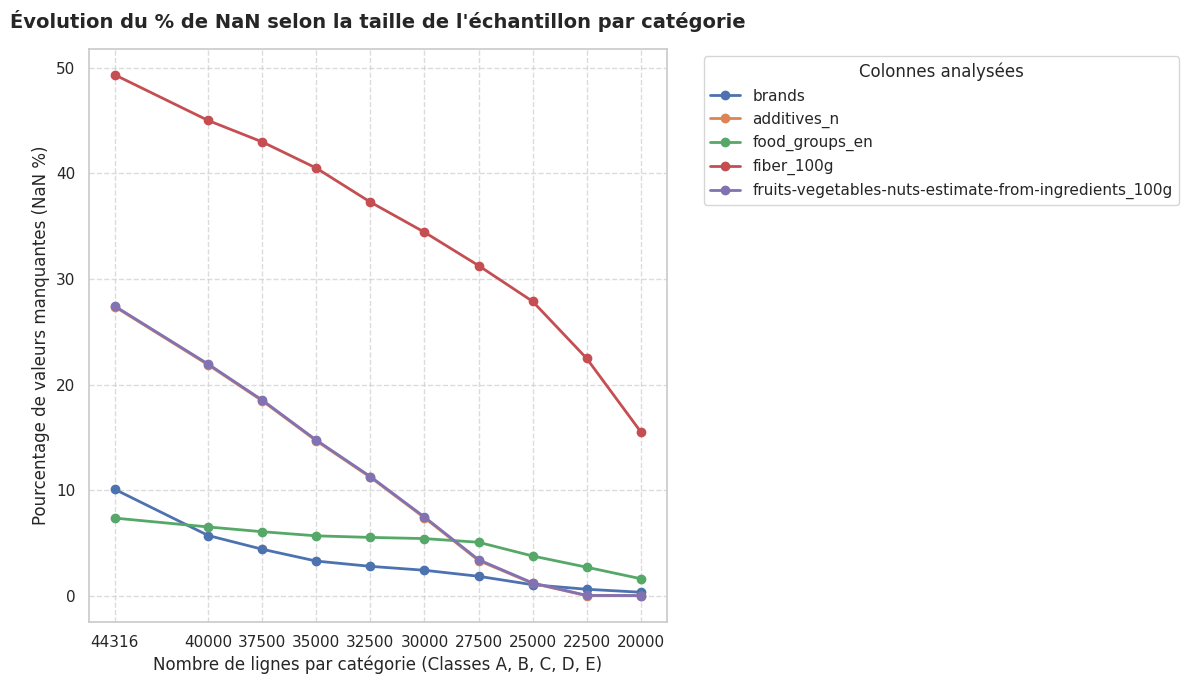

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style graphique
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# Inversion des colonnes pour avoir l'ordre croissant du nombre de lignes sur l'axe X
df_plot = df_comparatif_detaille.copy()
# On extrait uniquement le nombre de lignes par catégorie pour l'axe X (ex: '20000' depuis '20000/cat (Total: 100000)')
nb_lignes_categories = [int(col.split('/')[0]) for col in df_plot.columns]

# Tracer une courbe pour chaque colonne cible
for index, row in df_plot.iterrows():
    plt.plot(nb_lignes_categories, row.values, marker='o', linewidth=2, label=index)

# Personnalisation du graphique
plt.title("Évolution du % de NaN selon la taille de l'échantillon par catégorie", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Nombre de lignes par catégorie (Classes A, B, C, D, E)", fontsize=12)
plt.ylabel("Pourcentage de valeurs manquantes (NaN %)", fontsize=12)
plt.xticks(nb_lignes_categories)
plt.gca().invert_xaxis()  # Optionnel : inverser l'axe pour visualiser la réduction des NaN lorsqu'on réduit la taille
plt.legend(title="Colonnes analysées", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Affichage
plt.show()